# Boat tracks: heatmap, track map and port traffic

All S-model tracker CSV files are in `s_model_csv/<date>/` (copied from Google Drive `MDP recording`).
Some days also have a `_clean` or `_edited` version; `RUNS` in the Settings cell chooses which file is used.

1. **Settings**: which runs to load, and a shift (in metres) per camera position to move its tracks to the right place.
2. **Load** all runs into one table.
3. **Heatmap** of all detections on a satellite map.
4. **Track map**: every track drawn as a line.
5. **Entering / leaving the port**: count the tracks that cross a line in the camera image, and plot them per time of day.

Change the settings in the Settings cell and re-run everything (Run All).

In [25]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import contextily as ctx
import cv2
from scipy.ndimage import gaussian_filter

## 1. Settings

In [26]:
# Tracker output (S model): all CSV files are in s_model_csv/<date>/ next to this notebook
CSV_DIR = "s_model_csv"
# Google Drive, only used for the videos in section 5
DRIVE = r"G:\My Drive\MDP recording"

# The tracker runs to use: (date, camera position, CSV file in s_model_csv/<date>/)
RUNS = [
    ("2026-09-15", "P1", "s_P1_RAW_15-09_0530-1830.csv"),
    ("2026-09-21", "P1", "s_P1_RAW_21-09_0530-1830.csv"),
    ("2026-09-23", "P2", "s_P2_RAW_23-09_0530-1830.csv"),
    ("2026-09-24", "P2", "s_P2_RAW_24-09_0530-1830.csv"),
    ("2026-09-25", "P2", "s_P2_RAW_25-09_0530-1830.csv"),
    ("2026-09-26", "P2", "s_P2_RAW_26-09_0530-1830.csv"),
    ("2026-09-27", "P2", "s_P2_RAW_27-09_0530-1830.csv"),
    ("2026-09-28", "P2", "s_P2_RAW_28-09_0530-1830.csv"),
    ("2026-10-12", "P4L", "s_P4L_RAW_12-10_0530-1830_6fps.csv"),
    ("2026-10-13", "P4L", "s_P4L_RAW_13-10_0530-1830_6fps.csv"),
    ("2026-10-14", "P4L", "s_P4L_RAW_14-10_0530-1830_6fps.csv"),
    ("2026-10-15", "P4L", "s_P4L_RAW_15-10_0530-1830_6fps.csv"),
    ("2026-10-16", "P4L", "s_P4L_RAW_16-10_0530-1830_6fps.csv"),
    ("2026-10-17", "P4L", "s_P4L_RAW_17-10_0530-1830_6fps.csv"),
    ("2026-10-12", "P4R", "s_P4R_RAW_12-10_0530-1830_6fps.csv"),
    ("2026-10-13", "P4R", "s_P4R_RAW_13-10_0530-1830_6fps.csv"),
    ("2026-10-14", "P4R", "s_P4R_RAW_14-10_0530-1830_6fps.csv"),
    ("2026-10-15", "P4R", "s_P4R_RAW_15-10_0530-1830_6fps.csv"),
    ("2026-10-16", "P4R", "s_P4R_RAW_16-10_0530-1830_6fps.csv"),
    ("2026-10-17", "P4R", "s_P4R_RAW_17-10_0530-1830_6fps.csv"),
    ("2026-10-28", "P5", "s_P5_RAW_28-10_0530-1800_6fps.csv"),
    ("2026-10-29", "P5", "s_P5_RAW_29-10_0530-1800_6fps.csv"),
]

# Move all tracks of one camera position, in metres: (east, north).
# Negative = west / south. Example: (5, -3) moves everything 5 m east and 3 m south.
SHIFT_M = {
    "P1": (-18, -3),
    "P2": (0, 0),
    "P4L": (-10.74,-7.53),
    "P4R": (0,0),
    "P5": (-12.7, -4.8),
}

VIDEO_FPS = 12      # the videos are recorded at 12 frames per second
MIN_CONF = 0.30     # ignore detections the model is not sure about

# Drone photo (orthomosaic) used as background, on top of the satellite image
DRONE_TIF = r"C:\Users\apper\MDP_CameraLocalRuns\Drone footage\20261007_Canal_transparent_mosaic_group1 (1).tif"
DRONE_PIXEL_M = 0.25   # background resolution in metres (smaller = sharper, but slower)

## 2. Load all runs
Each row is one detection. Extra columns: `date`, `camera`, `time` (clock time of the detection) and `weight`.

Runs made at 6 fps (s model) only have every 2nd frame, so a boat gets half as many detections as in a 12 fps run.
`weight = 2` for those rows makes the heatmap treat all days the same.

In [27]:
def load_run(date, camera, file):
    path = file if os.path.isabs(file) else os.path.join(CSV_DIR, date, file)
    if not os.path.exists(path):
        print(f"skipped, file not found: {path}")
        return None
    if os.path.getsize(path) == 0:
        print(f"skipped, file is empty (tracker still running?): {path}")
        return None
    file = os.path.basename(path)

    df = pd.read_csv(path)
    df = df[df["conf"] >= MIN_CONF].dropna(subset=["lat", "lon"])
    df["date"] = date
    df["camera"] = camera

    # clock time: the video starts at the time in the file name, e.g. "..._0530-1830" -> 05:30
    start = file.split("_")[4][:4]
    video_start = pd.Timestamp(f"{date} {start[:2]}:{start[2:]}")
    df["time"] = video_start + pd.to_timedelta(df["frame"] / VIDEO_FPS, unit="s")

    # 6 fps runs only have even frame numbers
    df["weight"] = 2 if (df["frame"] % 2 == 0).all() else 1

    # shift this camera's positions by SHIFT_M metres (1 degree latitude = 111,320 m)
    east, north = SHIFT_M[camera]
    df["lat"] = df["lat"] + north / 111_320
    df["lon"] = df["lon"] + east / (111_320 * np.cos(np.radians(df["lat"])))

    print(f"{date} {camera}: {len(df):,} detections, {df.loc[df.track_id >= 0, 'track_id'].nunique()} tracks")
    return df


data = pd.concat([load_run(*run) for run in RUNS])   # runs that were skipped (None) are left out
print(f"total: {len(data):,} detections")

2026-09-15 P1: 73,933 detections, 693 tracks
2026-09-21 P1: 29,441 detections, 282 tracks
2026-09-23 P2: 90,779 detections, 1037 tracks
2026-09-24 P2: 97,353 detections, 1160 tracks
2026-09-25 P2: 88,365 detections, 1050 tracks
2026-09-26 P2: 131,680 detections, 1197 tracks
2026-09-27 P2: 69,930 detections, 477 tracks
2026-09-28 P2: 45,104 detections, 453 tracks
2026-10-12 P4L: 45,963 detections, 590 tracks
2026-10-13 P4L: 64,402 detections, 851 tracks
2026-10-14 P4L: 82,700 detections, 835 tracks
2026-10-15 P4L: 61,480 detections, 799 tracks
2026-10-16 P4L: 72,043 detections, 851 tracks
2026-10-17 P4L: 63,585 detections, 806 tracks
2026-10-12 P4R: 52,859 detections, 217 tracks
2026-10-13 P4R: 19,591 detections, 347 tracks
2026-10-14 P4R: 21,090 detections, 269 tracks
2026-10-15 P4R: 19,535 detections, 383 tracks
2026-10-16 P4R: 16,477 detections, 304 tracks
2026-10-17 P4R: 13,584 detections, 306 tracks
2026-10-28 P5: 25,164 detections, 186 tracks
2026-10-29 P5: 837 detections, 10 trac

## 3. Heatmap
Helper functions first: map coordinates and a satellite background.

In [28]:
def to_map_xy(lat, lon):
    """lat/lon in degrees -> x/y in metres of the web map (the same projection as the satellite tiles)."""
    R = 6_378_137
    x = R * np.radians(lon)
    y = R * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
    return x, y


def satellite(w, s, e, n):
    """Satellite image for the area w..e, s..n (web map metres). Tries a few sources / zoom levels."""
    google = "https://mt1.google.com/vt/lyrs=s&x={x}&y={y}&z={z}"
    for src, zoom in [(google, 19), (google, 18), (ctx.providers.Esri.WorldImagery, 18), (ctx.providers.Esri.WorldImagery, 17)]:
        try:
            img, extent = ctx.bounds2img(w, s, e, n, zoom=zoom, source=src)
            if img[..., :3].std() > 10:      # not an empty "no imagery" tile
                return img, extent
        except Exception as err:
            print("basemap failed:", err)
    return None, None


data["x"], data["y"] = to_map_xy(data["lat"].to_numpy(), data["lon"].to_numpy())

# map area: all detections plus a margin
pad = 60   # metres
w, e = data["x"].min() - pad, data["x"].max() + pad
s, n = data["y"].min() - pad, data["y"].max() + pad
background, background_extent = satellite(w, s, e, n)


def drone_photo(tif, pixel_m):
    """The drone photo in web map coordinates, at pixel_m metres per pixel.
    Reading the 700 MB file takes about a minute, so the result is saved next to this notebook
    and re-used the next time (delete the .npz file if the photo or DRONE_PIXEL_M changes)."""
    cache = f"drone_background_{pixel_m}m.npz"
    if os.path.exists(cache):
        saved = np.load(cache)
        return saved["img"], tuple(saved["extent"])
    if not os.path.exists(tif):
        print("drone photo not found:", tif)
        return None, None

    import rasterio
    from rasterio.vrt import WarpedVRT
    from rasterio.enums import Resampling
    with rasterio.open(tif) as src, WarpedVRT(src, crs="EPSG:3857") as vrt:   # convert to web map coordinates
        left, bottom, right, top = vrt.bounds
        rows, cols = int((top - bottom) / pixel_m), int((right - left) / pixel_m)
        img = vrt.read(out_shape=(vrt.count, rows, cols), resampling=Resampling.average)
    img = np.moveaxis(img, 0, -1)                  # (bands, rows, cols) -> (rows, cols, bands) for imshow
    extent = (left, right, bottom, top)
    np.savez_compressed(cache, img=img, extent=extent)
    return img, extent


drone, drone_extent = drone_photo(DRONE_TIF, DRONE_PIXEL_M)

### Clean up the detections
Before the heatmap, remove detections that are probably not moving boats:
- **short tracks**: fewer than `MIN_TRACK_POINTS` detections (flickering false detections)
- **stationary tracks**: the object moves less than `MIN_MOVE_M` metres in total (things on the shore)
- **moored**: the parts of a track where the boat moves slower than `MOORED_SPEED_MS` over `MOORED_WINDOW_S` seconds
  (moored boats, boats waiting at the quay). Without this, one boat lying still all day becomes the "busiest cell"
  of its camera and makes the rest of that camera almost invisible in the per-camera heatmap.
- **jumps**: a position more than `MAX_SPEED_MS` m/s away from the previous one in the same track (bad position, the scattered dots)
- **lonely cells**: map cells visited by fewer than `MIN_TRACKS_PER_CELL` different tracks

In [29]:
MIN_TRACK_POINTS = 10      # detections per track
MIN_MOVE_M = 15            # metres a track has to move in total
MOORED_WINDOW_S = 30       # moored check: compare a track's position in blocks of this many seconds
MOORED_SPEED_MS = 0.3      # slower than this (m/s) between neighbouring blocks = lying still
MAX_SPEED_MS = 15          # m/s (about 30 knots); faster jumps are bad positions
MIN_TRACKS_PER_CELL = 2    # different tracks per map cell
CLEAN_CELL_M = 2           # cell size for that last check, in metres

c = data[data["track_id"] >= 0].sort_values(["date", "camera", "track_id", "time"]).copy()
c["track"] = c["date"] + "_" + c["camera"] + "_" + c["track_id"].astype(str)
removed = {"untracked": len(data) - len(c)}

# short and stationary tracks
per_track = c.groupby("track").agg(points=("x", "size"),
                                   dx=("x", lambda v: v.max() - v.min()),
                                   dy=("y", lambda v: v.max() - v.min()))
short = per_track.index[per_track["points"] < MIN_TRACK_POINTS]
still = per_track.index[(per_track["points"] >= MIN_TRACK_POINTS) & (np.hypot(per_track["dx"], per_track["dy"]) < MIN_MOVE_M)]
removed["short tracks"] = c["track"].isin(short).sum()
removed["stationary tracks"] = c["track"].isin(still).sum()
c = c[~c["track"].isin(short) & ~c["track"].isin(still)]

# moored: the parts of a track where the boat lies still (moored, waiting at the quay).
# Split each track into blocks of MOORED_WINDOW_S seconds and take the middle position of each block.
# A block is "lying still" when it is close to both the block before and the block after it.
# Only those parts are removed, so a boat that sails in and then moors keeps its trip.
block = ((c["time"] - c["time"].dt.normalize()).dt.total_seconds() // MOORED_WINDOW_S).astype(int)
centre = c.groupby([c["track"], block])[["x", "y"]].median()
gc = centre.groupby(level=0)
to_prev = np.hypot(gc["x"].diff(), gc["y"].diff())
to_next = np.hypot(gc["x"].diff(-1), gc["y"].diff(-1))
lying_still = pd.concat([to_prev, to_next], axis=1).max(axis=1) < MOORED_SPEED_MS * MOORED_WINDOW_S
moored = lying_still.reindex(pd.MultiIndex.from_arrays([c["track"], block])).fillna(False).to_numpy(dtype=bool)
removed["moored"] = moored.sum()
c = c[~moored]

# jumps: speed from the previous detection of the same track
g = c.groupby("track")
dist = np.hypot(g["x"].diff(), g["y"].diff())
dt = g["time"].diff().dt.total_seconds()
jump = (dist / dt) > MAX_SPEED_MS
removed["jumps"] = jump.sum()
c = c[~jump]

# lonely cells
cell = (((c["x"] - w) // CLEAN_CELL_M).astype(int).astype(str) + "_" + ((c["y"] - s) // CLEAN_CELL_M).astype(int).astype(str))
tracks_in_cell = c.groupby(cell)["track"].transform("nunique")
removed["lonely cells"] = (tracks_in_cell < MIN_TRACKS_PER_CELL).sum()
clean = c[tracks_in_cell >= MIN_TRACKS_PER_CELL]

for why, count in removed.items():
    print(f"removed {count:>9,}  {why}")
print(f"kept    {len(clean):>9,} of {len(data):,} detections ({len(clean) / len(data):.0%})")

removed         6  untracked
removed    12,476  short tracks
removed    88,705  stationary tracks
removed   117,647  moored
removed     8,630  jumps
removed     8,078  lonely cells
kept      950,353 of 1,185,895 detections (80%)


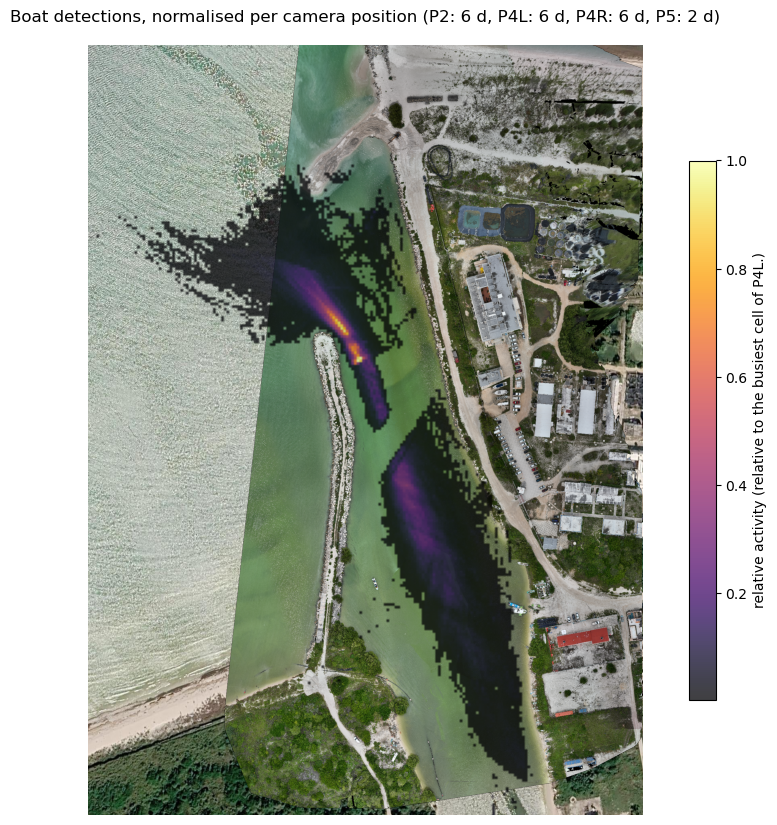

In [30]:
CELL_M = 2           # heatmap cell size in metres
BLUR_CELLS = 0          # smoothing
CAMERAS = ["P2", "P4L", "P4R", "P5"]   # which camera positions to show

# How to stop cameras with lots of data from hiding the others:
#   "none"       - raw detection counts, all days added up
#   "per_day"    - each camera's counts divided by its number of days (average day)
#   "per_camera" - each camera scaled so its busiest cell = 1 (every camera equally visible)
NORMALISE = "per_camera"

# Cameras recorded on the same days share one scale: P4R is divided by P4L's busiest cell
# (not its own), so P4L and P4R stay comparable to each other. Values above 1 are shown as 1.
SAME_SCALE_AS = {"P4R": "P4L", "P2": "P4L", "P5": "P4L"}

# Crop: the bottom stops where the drone photo stops; the left side starts this many metres
# left of the drone photo's left edge (bigger = more sea visible)
LEFT_MARGIN_M = 100

xbins = np.arange(w, e + CELL_M, CELL_M)
ybins = np.arange(s, n + CELL_M, CELL_M)


def camera_heatmap(camera):
    """Detections of one camera per cell (per average day unless NORMALISE == "none"); None if no data."""
    d = clean[clean["camera"] == camera]
    if d.empty:
        return None
    Hc, _, _ = np.histogram2d(d["x"], d["y"], bins=[xbins, ybins], weights=d["weight"])
    Hc = gaussian_filter(Hc, BLUR_CELLS).T    # .T: rows = y, as imshow expects
    if NORMALISE in ("per_day", "per_camera"):
        Hc = Hc / d["date"].nunique()
    return Hc


H = np.zeros((len(ybins) - 1, len(xbins) - 1))
for camera in CAMERAS:
    Hc = camera_heatmap(camera)
    if Hc is None:
        continue
    if NORMALISE == "per_camera":
        ref = SAME_SCALE_AS.get(camera, camera)
        Href = Hc if ref == camera else camera_heatmap(ref)
        scale = Href.max() if Href is not None else Hc.max()
        Hc = np.clip(Hc / scale, 0, 1)
        H = np.maximum(H, Hc)                 # where cameras overlap, keep the highest value
    else:
        H = H + Hc
H[H < H.max() * 0.002] = np.nan               # empty cells transparent, so the satellite shows

label = {"none": f"detections per {CELL_M} m cell (all days)",
         "per_day": f"detections per {CELL_M} m cell per day",
         "per_camera": "relative activity (relative to the busiest cell of P4L.)"}[NORMALISE]

fig, ax = plt.subplots(figsize=(12, 10))
if background is not None:
    ax.imshow(background, extent=background_extent)
if drone is not None:
    ax.imshow(drone, extent=drone_extent)        # transparent outside the flown area
im = ax.imshow(H, extent=(xbins[0], xbins[-1], ybins[0], ybins[-1]), origin="lower", cmap="inferno", alpha=0.75)
if drone is not None:
    ax.set_xlim(max(w, drone_extent[0] - LEFT_MARGIN_M), e); ax.set_ylim(drone_extent[2], n)
else:
    ax.set_xlim(w, e); ax.set_ylim(s, n)
ax.set_axis_off()
days = clean[clean["camera"].isin(CAMERAS)].groupby("camera")["date"].nunique()
ax.set_title(f"Boat detections, normalised per camera position (" + ", ".join(f"{c}: {days.get(c, 0)} d" for c in CAMERAS) + ")")
fig.colorbar(im, ax=ax, shrink=0.7, label=label)
plt.savefig(f"heatmap_all_runs_{NORMALISE}.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Track map
Every track as a thin line, one colour per camera position. Use this to choose the `SHIFT_M` values in the Settings cell:
the lines should lie on the water / in the channel. Change the shift, re-run, compare.

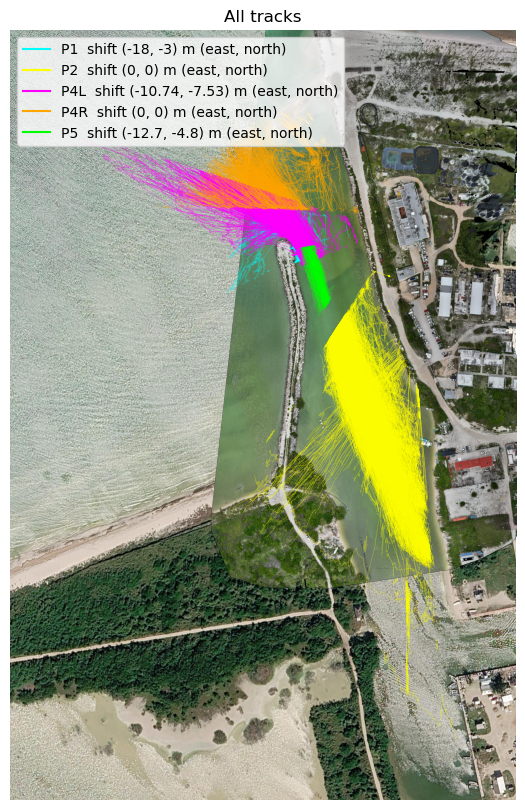

In [31]:
MIN_POINTS = 10                       # skip very short tracks (a few detections = usually noise)
COLORS = {"P1": "cyan", "P2": "yellow", "P4L": "magenta", "P4R": "orange", "P5": "lime"}

fig, ax = plt.subplots(figsize=(12, 10))
if background is not None:
    ax.imshow(background, extent=background_extent)
if drone is not None:
    ax.imshow(drone, extent=drone_extent)        # transparent outside the flown area

tracks = data[data["track_id"] >= 0]
for (date, camera, track_id), t in tracks.groupby(["date", "camera", "track_id"]):
    if len(t) >= MIN_POINTS:
        ax.plot(t["x"], t["y"], color=COLORS[camera], linewidth=0.5, alpha=0.3)

for camera, color in COLORS.items():
    ax.plot([], [], color=color, label=f"{camera}  shift {SHIFT_M[camera]} m (east, north)")
ax.legend(loc="upper left")
ax.set_xlim(w, e); ax.set_ylim(s, n); ax.set_axis_off()
ax.set_title("All tracks")
plt.savefig("tracks_all_runs.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Boats entering and leaving the port

For each camera there is a vertical **line in the camera image** (`x` in pixels). A track that starts on one side of
the line and ends on the other side has passed it. Moving to the right is `leaving` for both cameras
(P1: right = open sea; P2: as in the earlier notebook, line at x = 418).

First check the lines: the next cell draws them on a frame of each camera, with the detections of one day.

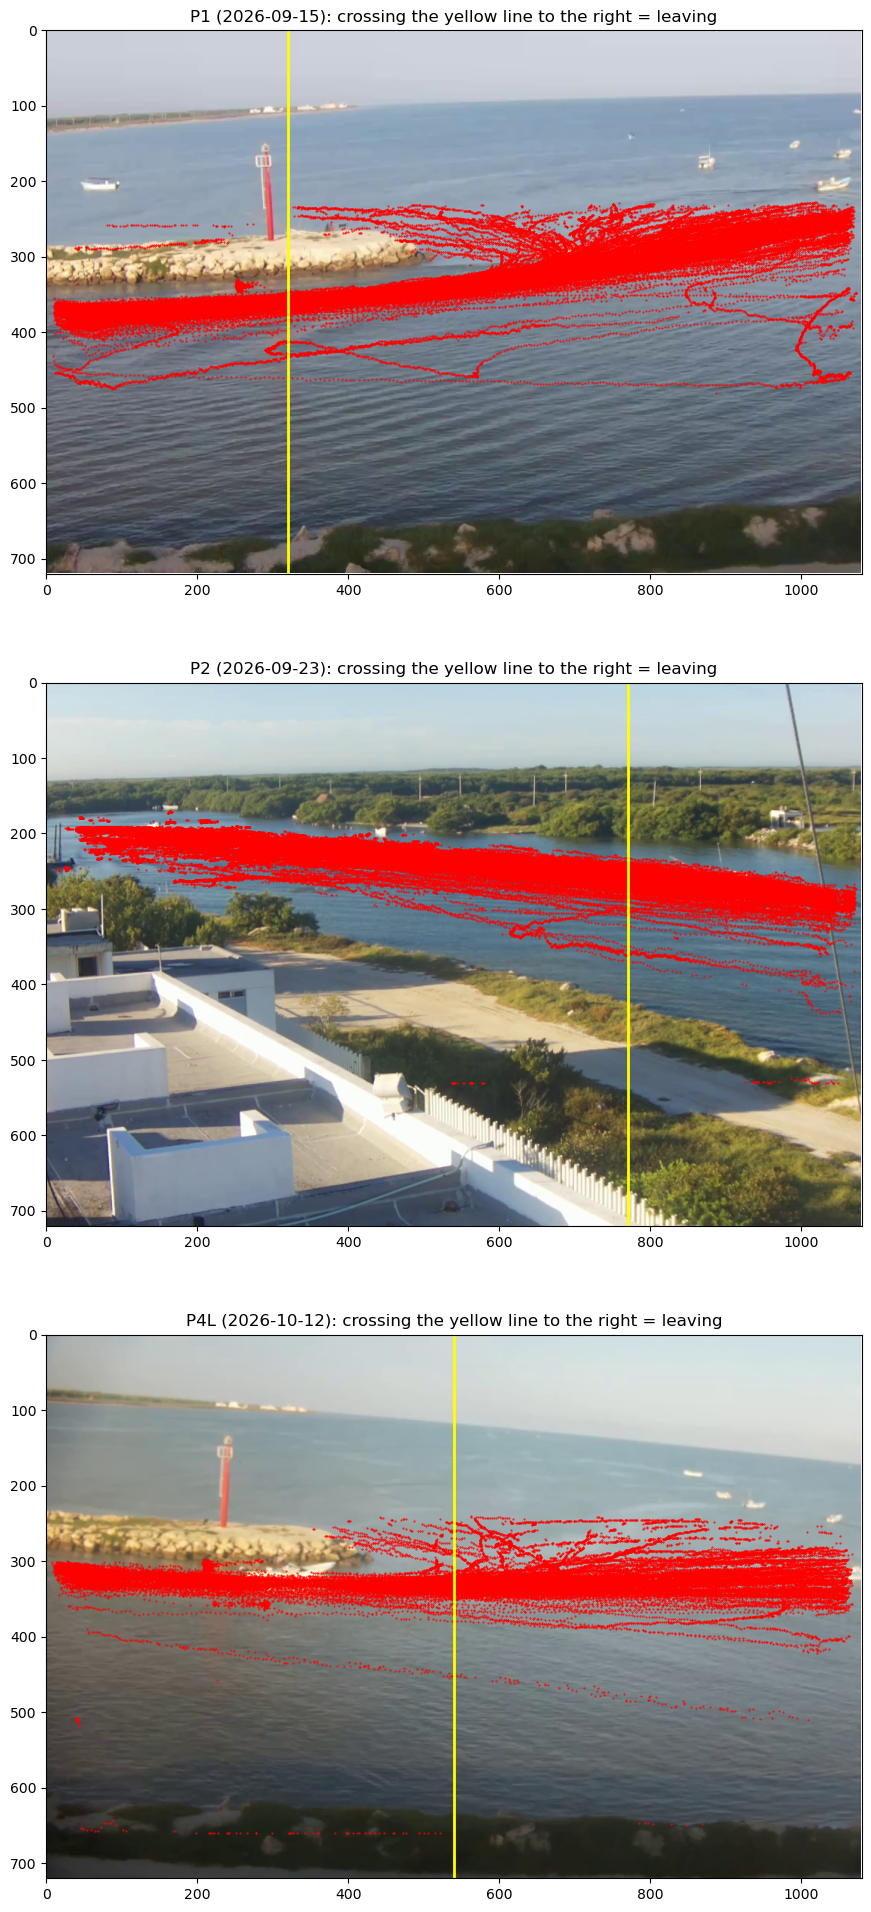

In [32]:
ENTRANCE = {
    #      x of the line (pixels), what crossing to the right means
    "P1": {"x": 320, "right_is": "leaving"},
    "P2": {"x": 770, "right_is": "leaving"},
    "P4L": {"x": 540, "right_is": "leaving"},   # right side of the image = north-west, like P1/P2
}

fig, axes = plt.subplots(len(ENTRANCE), 1, figsize=(12, 8 * len(ENTRANCE)))
for ax, camera in zip(np.atleast_1d(axes), ENTRANCE):
    date, _, file = next(r for r in RUNS if r[1] == camera)
    video_name = "_".join(file.split("_")[1:5]).removesuffix(".csv") + ".mp4"   # "s_P1_RAW_15-09_0530-1830.csv" -> "P1_RAW_15-09_0530-1830.mp4"
    cap = cv2.VideoCapture(os.path.join(DRIVE, date, video_name))
    cap.set(cv2.CAP_PROP_POS_FRAMES, 60000)          # a frame in daylight
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    day = data[(data["camera"] == camera) & (data["date"] == date)]
    ax.scatter(day["pixel_x"], day["pixel_y"], s=0.2, color="red")
    ax.axvline(ENTRANCE[camera]["x"], color="yellow", linewidth=2)
    ax.set_title(f"{camera} ({date}): crossing the yellow line to the right = {ENTRANCE[camera]['right_is']}")
    ax.set_xlim(0, 1080); ax.set_ylim(720, 0)
plt.show()

In [33]:
def crossings(df, camera):
    """One row per track that crossed the camera's line: when, and in which direction."""
    line_x = ENTRANCE[camera]["x"]
    right_is = ENTRANCE[camera]["right_is"]
    left_is = "entering" if right_is == "leaving" else "leaving"

    rows = []
    tracks = df[(df["camera"] == camera) & (df["track_id"] >= 0)]
    for (date, track_id), t in tracks.groupby(["date", "track_id"]):
        if len(t) < MIN_POINTS:
            continue
        t = t.sort_values("frame")
        starts_right = t["pixel_x"].iloc[0] >= line_x
        ends_right = t["pixel_x"].iloc[-1] >= line_x
        if starts_right == ends_right:
            continue                                     # did not pass the line
        on_end_side = (t["pixel_x"] >= line_x) == ends_right
        crossed_at = t.loc[on_end_side, "time"].iloc[0]  # first detection on the other side
        rows.append({"date": date, "camera": camera, "track_id": track_id,
                     "direction": right_is if ends_right else left_is, "time": crossed_at})
    return pd.DataFrame(rows)


passages = pd.concat([crossings(data, camera) for camera in ENTRANCE])
passages.to_csv("port_passages.csv", index=False)

# number of passages per day
print(passages.pivot_table(index=["date", "camera"], columns="direction", values="track_id", aggfunc="count", fill_value=0))

direction          entering  leaving
date       camera                   
2026-09-15 P1           171      254
2026-09-21 P1            61       97
2026-09-23 P2           236      256
2026-09-24 P2           272      254
2026-09-25 P2           228      276
2026-09-26 P2           267      266
2026-09-27 P2            98      109
2026-09-28 P2            45      135
2026-10-12 P4L          108      184
2026-10-13 P4L          194      287
2026-10-14 P4L          232      270
2026-10-15 P4L          197      308
2026-10-16 P4L          234      292
2026-10-17 P4L          215      279


Bar plot: average number of boats per day entering / leaving, per time of day.
Note: if a track breaks into two pieces right at the line, one boat can be counted twice;
`MIN_POINTS` (track map cell) removes most of the tiny pieces.

Average over 14 days (P1, P2, P4L):
  entering: 182.7 boats/day
  leaving: 233.4 boats/day


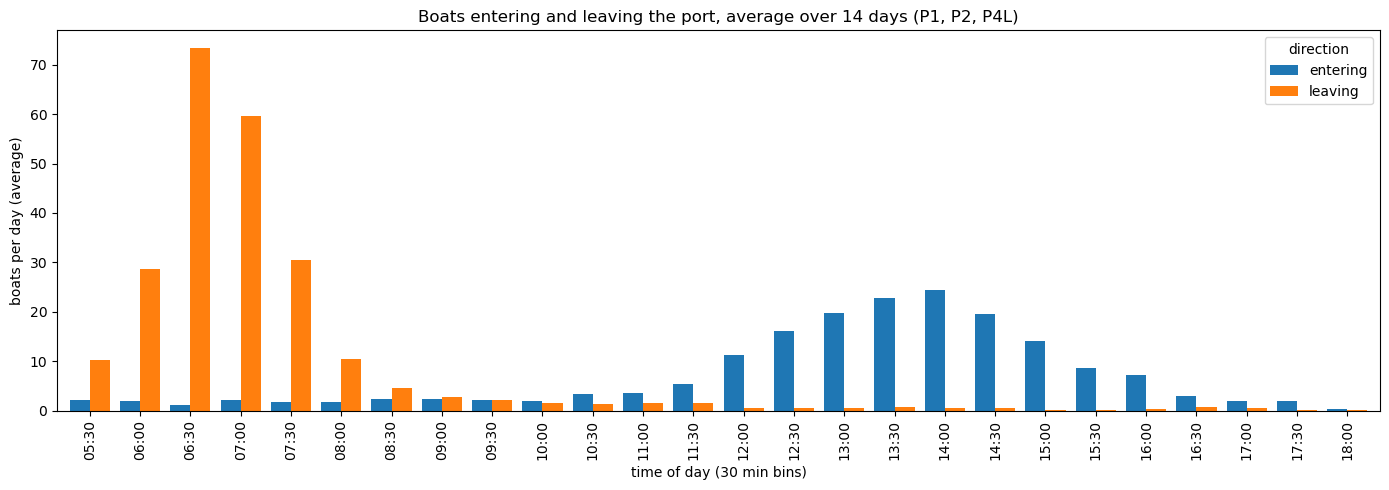

In [34]:
BIN_MIN = 30     # width of a time bin in minutes

passages["time_of_day"] = passages["time"].dt.floor(f"{BIN_MIN}min").dt.strftime("%H:%M")
days = passages["date"].nunique()
per_bin = passages.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0) / days

# average number of boats per day, entering and leaving
per_day = passages.groupby(["date", "direction"]).size().unstack(fill_value=0)
print(f"Average over {days} days ({', '.join(ENTRANCE)}):")
for direction, value in per_day.mean().items():
    print(f"  {direction}: {value:.1f} boats/day")

ax = per_bin.plot.bar(figsize=(14, 5), width=0.8, color={"entering": "tab:blue", "leaving": "tab:orange"})
ax.set_xlabel(f"time of day ({BIN_MIN} min bins)")
ax.set_ylabel("boats per day (average)")
ax.set_title(f"Boats entering and leaving the port, average over {days} days ({', '.join(ENTRANCE)})")
plt.tight_layout()
plt.savefig("port_traffic_per_time.png", dpi=200)
plt.show()

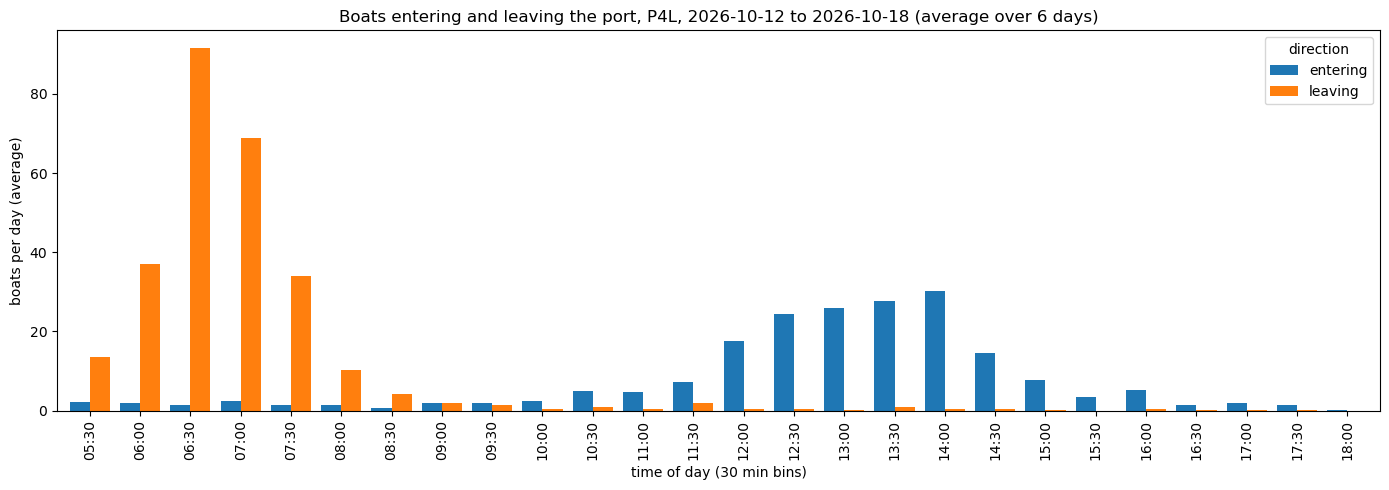

In [35]:
# The same bar plot for one camera and a date range
CAMERA = "P4L"
START, END = "2026-10-12", "2026-10-18"

p = passages[(passages["camera"] == CAMERA) & (passages["date"] >= START) & (passages["date"] <= END)]
days_p = p["date"].nunique()
per_bin_p = p.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0) / days_p

ax = per_bin_p.plot.bar(figsize=(14, 5), width=0.8, color={"entering": "tab:blue", "leaving": "tab:orange"})
ax.set_xlabel(f"time of day ({BIN_MIN} min bins)")
ax.set_ylabel("boats per day (average)")
ax.set_title(f"Boats entering and leaving the port, {CAMERA}, {START} to {END} (average over {days_p} days)")
plt.tight_layout()
plt.savefig(f"port_traffic_per_time_{CAMERA}_{START}_{END}.png", dpi=200)
plt.show()

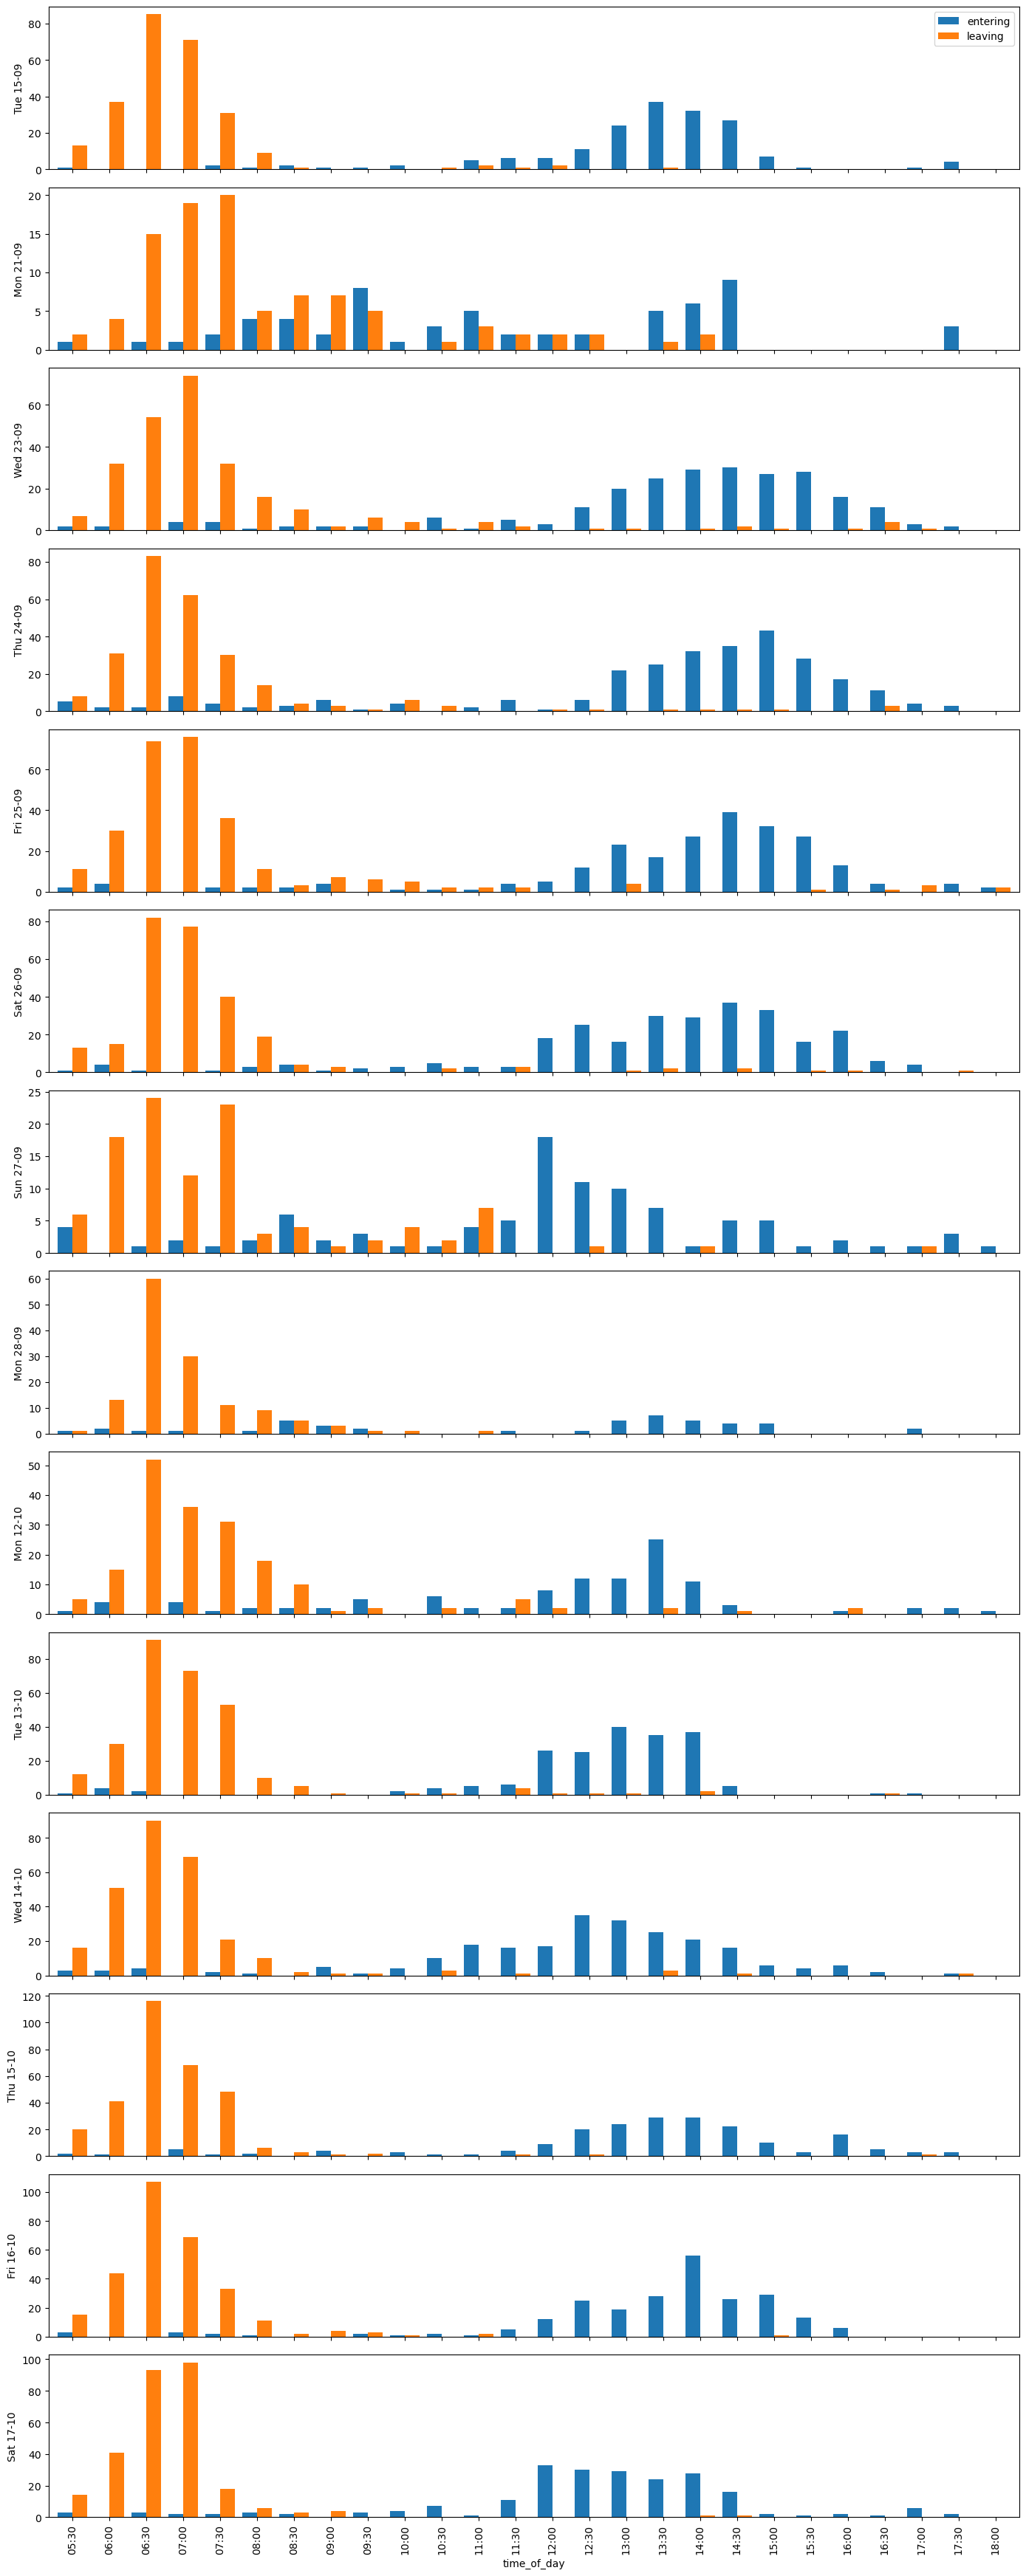

In [36]:
# The same, one small plot per day (to see if days differ)
dates = sorted(passages["date"].unique())
fig, axes = plt.subplots(len(dates), 1, figsize=(14, 2.5 * len(dates)), sharex=True)
for ax, date in zip(np.atleast_1d(axes), dates):
    p = passages[passages["date"] == date]
    counts = p.groupby(["time_of_day", "direction"]).size().unstack(fill_value=0).reindex(per_bin.index, fill_value=0)
    counts.plot.bar(ax=ax, width=0.8, legend=False, color={"entering": "tab:blue", "leaving": "tab:orange"})
    ax.set_ylabel(pd.Timestamp(date).strftime("%a %d-%m"))
np.atleast_1d(axes)[0].legend(loc="upper right")
plt.tight_layout()
plt.show()